# 11. Out-of-distribution evaluation on external data

**Question:** do the models selected on the main dataset still work on fallacy text written
by other people, in other styles? If the main-dataset scores rest on templates and topic
shortcuts (notebooks 06, 08), they should drop sharply here.

**Protocol.** Nothing is trained or tuned on the external data. The models are rebuilt
exactly as in notebook 10 (configurations from `results/selection.json`, fitted on the main
**train** split only) and applied once to:

| source | what it is | rows used |
|---|---|---|
| edu | LOGIC (Jin et al., 2022): short educational examples, labels mapped onto ours by the provider | rows with ≥1 of our 16 labels |
| comments | CoCoLoFa (Yeh et al., 2024; crowd-written news comments) + Touché 2026 (Reddit comments): 8 fallacy types + "No Fallacy" | fallacious rows with ≥1 of our 16 labels |

Labels outside our 16 (e.g. "Fallacy of Logic", "Appeal to Nature") cannot be predicted by
our models, so those rows are excluded here; the "No Fallacy" rows are used in notebook 12.
Scores are computed **only over the labels present in each source**, so a model is not
penalised for labels the source never annotates.

In [1]:
import sys, json, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.metrics import f1_score, precision_score, recall_score
from src.config import RESULTS, FIGURES, NEAR_DUP_LOW, NEAR_DUP_HIGH
from src.data import load_dataset, get_splits
from src.features import word_tfidf, word_bow
from src.models import logreg, linear_svm
from src.structural import TfidfPlusStructural
from src.evaluate import bootstrap_ci
from src.neardup import max_sim_to_train, bucket
from src.external import load_edu, load_comments

df, LABELS = load_dataset()
S = get_splits(df, LABELS)
X_tr, Y_tr, _ = S["train"]; X_te, Y_te, _ = S["test"]
sel = json.loads((RESULTS / "selection.json").read_text())
cw = lambda s: None if s in (None, "None") else "balanced"

edu = load_edu(LABELS); edu = edu[edu.in_schema].reset_index(drop=True)
red = load_comments(LABELS); red = red[red.in_schema].reset_index(drop=True)
print("edu rows:", len(edu), "| comment rows (fallacious, in-schema label):", len(red))
pd.DataFrame({"edu": edu[LABELS].sum(), "comments": red[LABELS].sum(), "main test": Y_te.sum(0)}).astype(int)

edu rows: 2094 | comment rows (fallacious, in-schema label): 363


,edu,comments,main test
Slippery Slope,0,88,485
Appeal to Authority,95,72,316
Bandwagon / Popularity,231,68,281
Hasty Generalization,439,73,207
False Cause / Causality,215,0,215
Appeal to Emotion,165,0,208
Composition,0,0,131
False Dilemma,140,62,146
Ad Hominem,300,0,119
Equivocation,46,0,86


## 11.1 How far are these texts from the training data?
Maximum TF-IDF cosine similarity of each external argument to any main-dataset training
argument (vectoriser fitted on train only), with the same buckets as notebooks 06 and 10.

In [2]:
rows = []
for name, texts in [("main test", X_te), ("edu", edu.argument), ("comments", red.argument)]:
    sim, _ = max_sim_to_train(X_tr, list(texts))
    b = pd.Series(bucket(sim, NEAR_DUP_LOW, NEAR_DUP_HIGH)).value_counts(normalize=True)
    rows.append({"set": name, "n": len(sim), "median max-cosine": np.median(sim),
                 **{f"% {k}": 100 * b.get(k, 0) for k in ["template-seen", "intermediate", "novel"]}})
dist = pd.DataFrame(rows); dist.round(2)

,set,n,median max-cosine,% template-seen,% intermediate,% novel
0,main test,1757,0.42,14.29,25.67,60.05
1,edu,2094,0.21,0.24,1.86,97.90
2,comments,363,0.17,0.00,0.00,100.00


The external texts are almost all *novel* by this measure, so there is no template overlap
to inflate the scores, and no external argument duplicates a training argument.

## 11.2 Frozen models, evaluated once

In [3]:
vec = word_tfidf(ngram_range=(1, 2)); A = vec.fit_transform(X_tr)
bow = word_bow(); Ab = bow.fit_transform(X_tr)
s1, s2, s, st = sel["LR-L1"], sel["LR-L2"], sel["LinearSVM"], sel["TFIDF+Structural-SVM"]
comb = TfidfPlusStructural(weight=st["weight"]).fit(X_tr)
models = {
    "Unigram BoW + LR (baseline)": (logreg("l2", 1.0).fit(Ab, Y_tr), bow),
    "TF-IDF LR-L1 (Lasso)": (logreg("l1", s1["C"], cw(s1["class_weight"])).fit(A, Y_tr), vec),
    "TF-IDF LR-L2 (ridge)": (logreg("l2", s2["C"], cw(s2["class_weight"])).fit(A, Y_tr), vec),
    "TF-IDF Linear SVM": (linear_svm(s["C"], cw(s["class_weight"])).fit(A, Y_tr), vec),
    "TF-IDF + structural Linear SVM": (linear_svm(st["C"], cw(st["class_weight"])).fit(comb.transform(X_tr), Y_tr), comb),
}

def evaluate(Y, texts, name):
    present = np.where(Y.sum(0) > 0)[0]            # labels this source annotates
    out = []
    for mname, (m, v) in models.items():
        P = m.predict(v.transform(list(texts)))
        Yp, Pp = Y[:, present], P[:, present]
        lo, hi = bootstrap_ci(Yp, Pp, "macro_f1", n_boot=1000)
        out.append({"set": name, "model": mname, "labels scored": len(present),
                    "macro_f1": f1_score(Yp, Pp, average="macro", zero_division=0), "macro_f1_95ci": f"[{lo:.3f}, {hi:.3f}]",
                    "micro_f1": f1_score(Yp, Pp, average="micro", zero_division=0),
                    "micro_precision": precision_score(Yp, Pp, average="micro", zero_division=0),
                    "micro_recall": recall_score(Yp, Pp, average="micro", zero_division=0),
                    "no label predicted": float((P.sum(1) == 0).mean())})
    return out, present

res = []
r_main, _ = evaluate(Y_te, X_te, "main test (all 16 labels)"); res += r_main
r_edu, p_edu = evaluate(edu[LABELS].values, edu.argument, "edu"); res += r_edu
r_red, p_red = evaluate(red[LABELS].values, red.argument, "comments"); res += r_red
# for the 5-label comparison, rebuild predictions restricted to the same columns
res_m5 = []
for mname, (m, v) in models.items():
    P = m.predict(v.transform(list(X_te)))[:, p_red]; Yp = Y_te[:, p_red]
    lo, hi = bootstrap_ci(Yp, P, "macro_f1", n_boot=1000)
    res_m5.append({"set": "main test (comments' 5 labels)", "model": mname, "labels scored": len(p_red),
                   "macro_f1": f1_score(Yp, P, average="macro", zero_division=0), "macro_f1_95ci": f"[{lo:.3f}, {hi:.3f}]",
                   "micro_f1": f1_score(Yp, P, average="micro", zero_division=0),
                   "micro_precision": precision_score(Yp, P, average="micro", zero_division=0),
                   "micro_recall": recall_score(Yp, P, average="micro", zero_division=0), "no label predicted": np.nan})
res = pd.DataFrame(res + res_m5)
res.to_csv(RESULTS / "ood_results.csv", index=False)
res.pivot(index="model", columns="set", values="macro_f1")[
    ["main test (all 16 labels)", "edu", "main test (comments' 5 labels)", "comments"]].round(3)

set,main test (all 16 labels),edu,main test (comments' 5 labels),comments
model,,,,
TF-IDF + structural Linear SVM,0.804,0.331,0.820,0.328
TF-IDF LR-L1 (Lasso),0.773,0.314,0.787,0.312
TF-IDF LR-L2 (ridge),0.789,0.334,0.819,0.341
TF-IDF Linear SVM,0.805,0.327,0.824,0.326
Unigram BoW + LR (baseline),0.751,0.318,0.787,0.339


In [4]:
res[["set", "model", "macro_f1", "macro_f1_95ci", "micro_precision", "micro_recall", "no label predicted"]].round(3)

,set,model,macro_f1,macro_f1_95ci,micro_precision,micro_recall,no label predicted
0,main test (all 16 labels),Unigram BoW + LR (baseline),0.751,"[0.699, 0.786]",0.852,0.743,0.097
1,main test (all 16 labels),TF-IDF LR-L1 (Lasso),0.773,"[0.729, 0.805]",0.818,0.780,0.054
2,main test (all 16 labels),TF-IDF LR-L2 (ridge),0.789,"[0.746, 0.820]",0.840,0.809,0.044
3,main test (all 16 labels),TF-IDF Linear SVM,0.805,"[0.764, 0.834]",0.830,0.834,0.035
4,main test (all 16 labels),TF-IDF + structural Linear SVM,0.804,"[0.761, 0.834]",0.828,0.829,0.039
5,edu,Unigram BoW + LR (baseline),0.318,"[0.269, 0.357]",0.508,0.244,0.556
6,edu,TF-IDF LR-L1 (Lasso),0.314,"[0.290, 0.335]",0.414,0.356,0.300
7,edu,TF-IDF LR-L2 (ridge),0.334,"[0.313, 0.353]",0.520,0.344,0.392
8,edu,TF-IDF Linear SVM,0.327,"[0.306, 0.344]",0.516,0.345,0.383
9,edu,TF-IDF + structural Linear SVM,0.331,"[0.309, 0.349]",0.483,0.344,0.375


Reading the table: compare *edu* with the main test, and *comments* with the main test scored
on the same five labels. "no label predicted" is the share of arguments for which the model
finds no fallacy at all, although every one of them contains one.

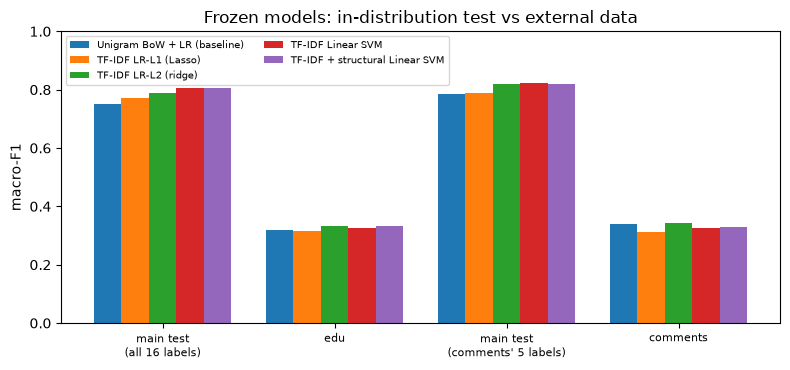

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.8))
sets = ["main test (all 16 labels)", "edu", "main test (comments' 5 labels)", "comments"]
mods = list(models); w = 0.16
for i, mname in enumerate(mods):
    g = res[res.model == mname].set_index("set").loc[sets]
    ax.bar(np.arange(4) + i * w, g.macro_f1, w, label=mname)
ax.set_xticks(np.arange(4) + 2 * w); ax.set_xticklabels([s.replace(" (", "\n(") for s in sets], fontsize=8)
ax.set_ylabel("macro-F1"); ax.set_ylim(0, 1); ax.legend(fontsize=7, ncol=2)
ax.set_title("Frozen models: in-distribution test vs external data")
plt.tight_layout(); plt.savefig(FIGURES / "ood_macro_f1.png", dpi=150); plt.show()

## 11.3 Per-label F1 (linear SVM)

In [6]:
m, v = models["TF-IDF Linear SVM"]
def per_label(Y, texts):
    P = m.predict(v.transform(list(texts)))
    return pd.Series(f1_score(Y, P, average=None, zero_division=0), index=LABELS), pd.Series(Y.sum(0), index=LABELS)
f_te, n_te = per_label(Y_te, X_te); f_edu, n_edu = per_label(edu[LABELS].values, edu.argument)
f_red, n_red = per_label(red[LABELS].values, red.argument)
pl = pd.DataFrame({"main test F1": f_te, "main n": n_te, "edu F1": f_edu.where(n_edu > 0), "edu n": n_edu,
                   "comments F1": f_red.where(n_red > 0), "comments n": n_red})
pl.to_csv(RESULTS / "ood_per_label.csv"); pl.round(3)

,main test F1,main n,edu F1,edu n,comments F1,comments n
Slippery Slope,0.906,485,NaN,0,0.504,88
Appeal to Authority,0.860,316,0.431,95,0.295,72
Bandwagon / Popularity,0.802,281,0.583,231,0.389,68
Hasty Generalization,0.714,207,0.326,439,0.169,73
False Cause / Causality,0.819,215,0.555,215,NaN,0
Appeal to Emotion,0.844,208,0.296,165,NaN,0
Composition,0.797,131,NaN,0,NaN,0
False Dilemma,0.840,146,0.648,140,0.273,62
Ad Hominem,0.783,119,0.455,300,NaN,0
Equivocation,0.873,86,0.042,46,NaN,0


## 11.4 Examples the SVM gets wrong on external data

In [7]:
pd.set_option("display.max_colwidth", 220)
P_edu = m.predict(v.transform(list(edu.argument)))
edu_pred = ["; ".join(np.array(LABELS)[r == 1]) or "(none)" for r in P_edu]
ex = edu.assign(predicted=edu_pred)
ex = ex[[set(p.split("; ")) .isdisjoint(set(t.split("; "))) for p, t in zip(ex.predicted, ex.fallacies)]]
ex.sample(8, random_state=0)[["argument", "fallacies", "predicted"]]

,argument,fallacies,predicted
1700,I shouldn't have to pay for my parking ticket. There are far more dangerous offenses people commit. They should have to pay.,Red Herring,(none)
1155,Researchers are frauds who don’t earn their salaries,Ad Hominem,(none)
921,SM 3: Polls concerning global warming,Bandwagon / Popularity,(none)
57,"""Even though it's only the first day, I can tell this is going to be a boring course.""",Hasty Generalization,(none)
226,"If you allow one student to take an online course, soon\neveryone will want to, and the schools will be empty.",Hasty Generalization,Slippery Slope
357,"Don't use iPhones. Teachers use iPhones and teachers are extremely dorky. If you use an iPhone, you will be dorky like a teacher!",Hasty Generalization,Slippery Slope
416,"Every time that rooster crows, the sun comes up. That rooster must be very powerful and important!",False Cause / Causality,(none)
1824,"Hi, I’m Troy McClure. You might remember me from such films as The Day the Peacock Died. After filming scenes with feathered co-stars all day, there’s nothing I enjoy more than a bucket of Buster’s Chicken. It’s chic...",Appeal to Authority,(none)


## 11.5 Caveat: part of the drop is label-schema mismatch, not model error
edu has **no Slippery Slope label at all**, yet some of its examples are textbook slippery
slopes filed under another name (the provider mapped LOGIC's categories onto ours). We count
how many edu "errors" are a Slippery Slope prediction on a text with chain-of-consequence
wording, which is arguably correct.

In [8]:
chain = edu.argument.str.contains(r"\b(soon|next|eventually|lead to|leads to|before you know it|then)\b", case=False, regex=True)
pred_ss = P_edu[:, LABELS.index("Slippery Slope")] == 1
print(f"edu arguments predicted Slippery Slope: {pred_ss.sum()} ({pred_ss.mean():.1%}); "
      f"of these, {(pred_ss & chain).sum()} contain chain-of-consequence wording")
pd.crosstab(edu.fallacies[pred_ss & chain].str.split("; ").str[0], "count").sort_values("count", ascending=False).head(6)

edu arguments predicted Slippery Slope: 109 (5.2%); of these, 78 contain chain-of-consequence wording


col_0,count
fallacies,
Hasty Generalization,70
Appeal to Emotion,2
Straw Man,2
Red Herring,2
False Cause / Causality,1
False Dilemma,1


These cases make the edu score a **lower bound**: a schema-perfect relabelling would credit
some of them. They are too few to explain a drop from 0.80 to 0.33, and the comment data,
whose five labels map directly onto ours, shows the same collapse.

In [9]:
summary = {"distance": dist.to_dict("records"), "results": res.to_dict("records"),
           "per_label": pl.reset_index(names="label").replace({np.nan: None}).to_dict("records"),
           "n_edu": int(len(edu)), "n_comments": int(len(red)),
           "edu_labels_scored": [LABELS[i] for i in p_edu], "comments_labels_scored": [LABELS[i] for i in p_red],
           "edu_pred_ss": int(pred_ss.sum()), "edu_pred_ss_chain": int((pred_ss & chain).sum())}
(RESULTS / "ood_summary.json").write_text(json.dumps(summary, indent=2, default=float)); print("saved")

saved
